**18 | Out-of-Fold CNN Confidence and Error Audit**

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Research question:** How confident is the existing 1,000-cap Weighted CNN when correct or incorrect, especially on Shuffling and stair activities? Use exactly 400 optimiser steps across three participant-independent GroupKFold folds, preserving Stage 17's architecture and training policy. These are **uncalibrated softmax** diagnostics on development data, not independent testing or a clinical uncertainty estimate.

**01. Imports and reusable code**

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

# Register reusable core and HARTH study-specific functions.
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open this notebook inside the repository.")
    root = root.parent
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort
from core.temporal_cnn import (
    train_temporal_cnn_fixed_steps, predict_temporal_cnn_probabilities,
)
from core.prediction_reliability import audit_prediction_confidence

print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

PyTorch: 2.12.1+cpu | CUDA: False


**02. Reconstruct the Stage 17 development dataset**

Use the identical nested recording adapter and source class definitions. Only the base-500 rows may enter Validation; 1,000-cap samples are available only to Train participants. The original Test IDs remain excluded.

In [2]:
# Preserve the same protected subjects and documented eight-class task.
RESERVED_TEST = {"S023", "S032"}
SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,
    window_size=100, step_size=50, sampling_rate=50,
)
base_rows = np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))
y = metadata["label"].to_numpy()
group_ids = metadata["subject_id"].to_numpy()
assert len(SUBJECTS) == 29 and len(base_rows) == 14201
assert not (set(group_ids) & RESERVED_TEST)
print("Expanded input:", X.shape, "| Original Validation candidates:", len(base_rows))

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Expanded input: (28201, 6, 100) | Original Validation candidates: 14201


**03. Train the predeclared CNN in each development fold**

Each fold has a new model, the same **400-step fixed budget** and inverse-square-root class weighting based only on Fold Train. Validation softmax predictions are collected at the final step, with the original source-row ID.

In [3]:
# Produce aligned out-of-fold probabilities without touching reserved Test.
FOLDS, STEPS = 3, 400
device = "cuda" if torch.cuda.is_available() else "cpu"
folds = GroupKFold(n_splits=FOLDS)
records, fold_metrics = [], []
for fold, (tr, va) in enumerate(
    folds.split(np.zeros(len(base_rows)), y[base_rows], groups=group_ids[base_rows]),
    start=1,
):
    base_train = base_rows[tr]
    validation = base_rows[va]
    train_subjects = set(group_ids[base_train])
    validation_subjects = set(group_ids[validation])
    assert not (train_subjects & validation_subjects)
    train_rows = np.flatnonzero(np.isin(group_ids, list(train_subjects)))

    # Fit 1,000-cap Weighted CNN on Train people only.
    model, history, predicted, train_stats = train_temporal_cnn_fixed_steps(
        X_train=X[train_rows], y_train=y[train_rows],
        X_validation=X[validation], y_validation=y[validation],
        classes=TASK_CLASSES, max_steps=STEPS, eval_every=100,
        batch_size=128, learning_rate=1e-3, seed=42,
        device=device, class_weighting="inverse_sqrt",
    )
    probabilities = predict_temporal_cnn_probabilities(
        model, X[validation], train_stats, TASK_CLASSES,
        batch_size=256, device=device,
    )
    assert np.array_equal(
        np.asarray(TASK_CLASSES)[probabilities.argmax(axis=1)], predicted
    ), "Probability inference must match the final-step prediction."
    records.append(pd.DataFrame({
        "fold": fold, "source_row": validation,
        "subject_id": group_ids[validation],
        "true_label": y[validation],
        **{f"prob_{code}": probabilities[:, i]
           for i, code in enumerate(TASK_CLASSES)},
    }))
    fold_metrics.append({
        "fold": fold, "validation_subjects": len(validation_subjects),
        "validation_windows": len(validation),
        "macro_f1": f1_score(
            y[validation], predicted, labels=TASK_CLASSES,
            average="macro", zero_division=0,
        ),
    })
    print("Completed fold", fold)
oof = pd.concat(records, ignore_index=True).sort_values("source_row")
display(pd.DataFrame(fold_metrics).round(4))

Step 100/400 | loss=0.8877 | Validation Macro F1=0.5860
Step 200/400 | loss=0.4701 | Validation Macro F1=0.7490
Step 300/400 | loss=0.3450 | Validation Macro F1=0.7403
Step 400/400 | loss=0.2571 | Validation Macro F1=0.7588
Completed fold 1
Step 100/400 | loss=0.8686 | Validation Macro F1=0.5882
Step 200/400 | loss=0.4489 | Validation Macro F1=0.6820
Step 300/400 | loss=0.3275 | Validation Macro F1=0.7783
Step 400/400 | loss=0.2570 | Validation Macro F1=0.7976
Completed fold 2
Step 100/400 | loss=0.8687 | Validation Macro F1=0.5762
Step 200/400 | loss=0.4949 | Validation Macro F1=0.6086
Step 300/400 | loss=0.3644 | Validation Macro F1=0.7361
Step 400/400 | loss=0.3287 | Validation Macro F1=0.8218
Completed fold 3


,fold,validation_subjects,validation_windows,macro_f1
0,1,10,5000,0.7588
1,2,10,4701,0.7976
2,3,9,4500,0.8218


**04. Verify out-of-fold provenance and compute descriptive confidence metrics**

Each base-500 development row must appear in precisely one held-out fold. The probability table has columns in the fixed original activity-code order.

In [4]:
# Audit probability rows before drawing any inference.
assert len(oof) == len(base_rows)
assert oof["source_row"].is_unique
np.testing.assert_array_equal(oof["source_row"].to_numpy(), np.sort(base_rows))
np.testing.assert_array_equal(
    oof["true_label"].to_numpy(), y[np.sort(base_rows)]
)
prob_columns = [f"prob_{code}" for code in TASK_CLASSES]
details, reliability, by_subject, summary = audit_prediction_confidence(
    y_true=oof["true_label"].to_numpy(),
    probabilities=oof[prob_columns].to_numpy(),
    subjects=oof["subject_id"].to_numpy(),
    classes=TASK_CLASSES, n_bins=10,
)
details["fold"] = oof["fold"].to_numpy()
details["source_row"] = oof["source_row"].to_numpy()
display(pd.DataFrame([summary]).round(4))
display(reliability.round(4))
print("Note: uncalibrated softmax, not validated uncertainty.")

,windows,accuracy,mean_confidence,ece_10_bins,multiclass_brier,high_confidence_errors_0_90
0,14201,0.9458,0.9005,0.0453,0.0905,40


,bin,lower,upper,windows,mean_confidence,observed_accuracy
0,0,0.0,0.1,0,NaN,NaN
1,1,0.1,0.2,0,NaN,NaN
2,2,0.2,0.3,53,0.2753,0.3962
3,3,0.3,0.4,289,0.3593,0.4360
4,4,0.4,0.5,344,0.4534,0.5698
5,5,0.5,0.6,404,0.5508,0.7079
6,6,0.6,0.7,452,0.6512,0.7854
7,7,0.7,0.8,767,0.7565,0.8683
8,8,0.8,0.9,1576,0.8562,0.9549
9,9,0.9,1.0,10316,0.9758,0.9961


Note: uncalibrated softmax, not validated uncertainty.


**05. Reliability diagram and confidence distribution**

Compare average softmax confidence with empirical accuracy in fixed-width bins. These observations are correlated within recordings; ECE is descriptive and sensitive to binning.

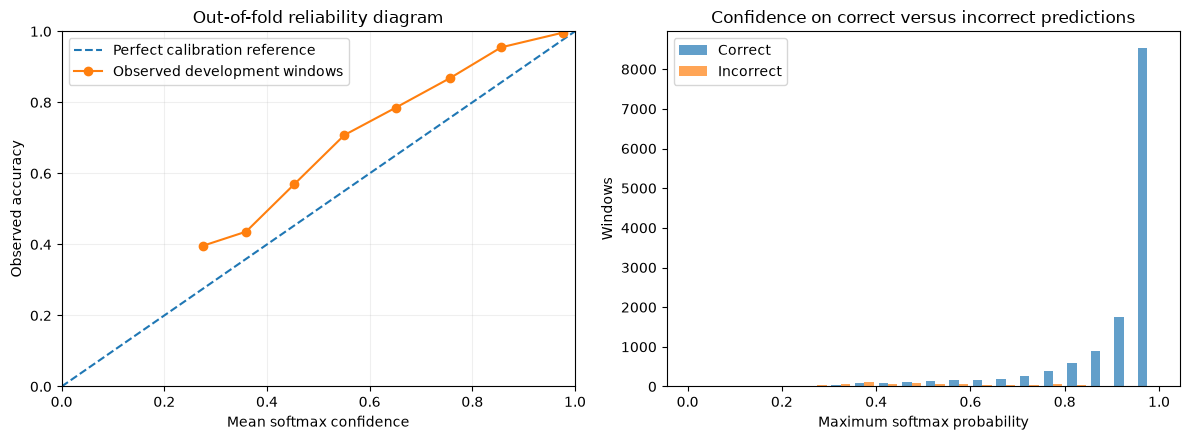

In [5]:
# Plot observed accuracy versus softmax confidence for non-empty bins.
used = reliability.loc[reliability["windows"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration reference")
axes[0].plot(
    used["mean_confidence"], used["observed_accuracy"],
    marker="o", label="Observed development windows",
)
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean softmax confidence",
            ylabel="Observed accuracy", title="Out-of-fold reliability diagram")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Contrast confidence of correct and incorrect windows.
correct = details.loc[details["correct"], "confidence"]
wrong = details.loc[~details["correct"], "confidence"]
axes[1].hist([correct, wrong], bins=np.linspace(0, 1, 21),
             label=["Correct", "Incorrect"], alpha=0.7)
axes[1].set(xlabel="Maximum softmax probability", ylabel="Windows",
            title="Confidence on correct versus incorrect predictions")
axes[1].legend()
fig.tight_layout()
plt.show()

**06. Audit Shuffling, stairs and confident misclassifications**

Prior stages found uneven class recall. Report support, accuracy and wrong predictions with high softmax values separately, without treating confidence as a clinically actionable probability.

In [6]:
# Inspect held-out class-specific errors, keeping original code meanings.
class_table = []
for code in TASK_CLASSES:
    part = details.loc[details["true_label"] == code]
    mistakes = part.loc[~part["correct"]]
    class_table.append({
        "class": ACTIVITY_NAMES[code], "support": len(part),
        "recall": float(part["correct"].mean()) if len(part) else np.nan,
        "errors": len(mistakes),
        "high_confidence_errors_0_90":
            int((mistakes["confidence"] >= 0.90).sum()),
        "mean_error_confidence":
            float(mistakes["confidence"].mean()) if len(mistakes) else np.nan,
    })
class_report = pd.DataFrame(class_table)
display(class_report.round(4))
display(by_subject.sort_values("high_confidence_errors", ascending=False).round(4))

# Display actual source-label confusion pairs among high-confidence errors.
confident_errors = details.loc[
    (~details["correct"]) & (details["confidence"] >= 0.9)
]
confusion_pairs = (confident_errors
    .groupby(["true_label", "predicted_label"])
    .size().rename("windows").reset_index()
    .sort_values("windows", ascending=False))
display(confusion_pairs.head(15))

,class,support,recall,errors,high_confidence_errors_0_90,mean_error_confidence
0,Walking,3591,0.9293,254,3,0.4833
1,Running,1028,0.9951,5,0,0.5581
2,Shuffling,219,0.1233,192,9,0.5641
3,Stairs ascending,192,0.7448,49,0,0.5197
4,Stairs descending,182,0.6538,63,8,0.6720
5,Standing,2227,0.9537,103,20,0.5671
6,Sitting,5599,0.9816,103,0,0.7342
7,Lying,1163,0.9991,1,0,0.5317


,subject_id,windows,accuracy,errors,mean_error_confidence,high_confidence_errors
26,S036,500,0.9340,33,0.5799,9
9,S017,500,0.9320,34,0.6793,7
10,S018,500,0.9340,33,0.6813,6
5,S013,500,0.9120,44,0.5533,5
0,S006,500,0.9740,13,0.5153,3
6,S014,500,0.9380,31,0.5089,2
2,S009,201,0.8955,21,0.6018,2
16,S025,500,0.9640,18,0.6459,2
7,S015,500,0.9720,14,0.6657,1
13,S021,500,0.9220,39,0.5723,1


,true_label,predicted_label,windows
5,6,7,20
4,5,1,8
2,3,6,4
0,1,6,3
1,3,1,3
3,3,7,2


**07. Quality gate and interpretation**

The current study evaluates **uncalibrated** probability scores, not the efficacy of confidence-based refusal or an uncertainty-aware decision policy. No temperature scaling, threshold tuning or external calibration is performed.

In [7]:
# Confirm exact fold coverage and an untouched protected Test boundary.
assert len(details) == 14201
assert oof["source_row"].is_unique
assert details["subject_id"].nunique() == 29
assert not (set(details["subject_id"]) & RESERVED_TEST)
assert int(reliability["windows"].sum()) == len(details)
assert np.allclose(oof[prob_columns].sum(axis=1), 1, atol=1e-5)
assert 0 <= summary["accuracy"] <= 1
assert 0 <= summary["ece_10_bins"] <= 1
print("Out-of-fold softmax confidence audit: PASSED")
print("Original reserved Test used: NO")
print("Calibration or clinical uncertainty validity established: NO")

Out-of-fold softmax confidence audit: PASSED
Original reserved Test used: NO
Calibration or clinical uncertainty validity established: NO
